## Stage 1 — Dataset Loading and Structural Inspection

In [12]:
import sys
import pandas as pd
import numpy as np
import matplotlib
import seaborn
import sklearn

print("Python:", sys.executable)
print("All required libraries imported successfully!")

Python: c:\Users\Diya\AppData\Local\Python\pythoncore-3.12-64\python.exe
All required libraries imported successfully!


### 1.1 Library imports and dataset path

In [13]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

DATA_DIR = Path(
    r"D:\ML-Project-202618011-And-202618049-\data"
)

print("Libraries imported successfully!")
print("Data folder exists:", DATA_DIR.exists())


Libraries imported successfully!
Data folder exists: True


### 1.2 Dataset file inspection

In [14]:
for file in DATA_DIR.iterdir():
    if file.is_file():
        print(
            f"{file.name} | "
            f"{file.stat().st_size / (1024**2):.2f} MB"
        )


dashboard_clean_15k.csv | 1.83 MB
train_batched.csv | 1373.10 MB


### 1.3 Load the smaller dataset

In [15]:
file_path = DATA_DIR / "dashboard_clean_15k.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())


Dataset loaded successfully!
Rows: 20000
Columns: 21


,city_id,store_id,management_group_id,first_category_id,second_category_id,third_category_id,product_id,dt,sale_amount,discount,holiday_flag,activity_flag,precpt,avg_temperature,avg_humidity,avg_wind_level,total_stockout_hours,total_stock_count,estimated_demand,unit_price_estimate,lost_revenue
0,10,23,6,4,28,142,351,2024-04-18,0.8,1.000,0,0,1.3321,18.70,73.96,1.45,12,4.0,0.7,120,0.0
1,0,189,6,4,28,161,136,2024-05-07,0.5,0.799,0,1,0.7694,21.08,74.25,1.26,0,0.0,0.7,120,24.0
2,13,642,2,31,79,230,530,2024-06-04,0.8,1.000,0,0,6.7654,27.29,84.27,1.77,0,0.0,0.7,120,0.0
3,12,610,6,4,28,167,775,2024-06-20,1.9,0.584,0,1,8.7860,28.28,86.66,1.93,0,0.0,0.7,120,0.0
4,7,824,6,20,50,229,309,2024-04-24,0.2,1.000,0,0,18.1918,24.69,82.06,1.77,14,12.0,0.7,120,60.0


### 1.4 Structural inspection

In [16]:

print("Column names:")
for column in df.columns:
    print(column)

print("\nData types and non-null counts:")
df.info()


Column names:
city_id
store_id
management_group_id
first_category_id
second_category_id
third_category_id
product_id
dt
sale_amount
discount
holiday_flag
activity_flag
precpt
avg_temperature
avg_humidity
avg_wind_level
total_stockout_hours
total_stock_count
estimated_demand
unit_price_estimate
lost_revenue

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   city_id               20000 non-null  int64  
 1   store_id              20000 non-null  int64  
 2   management_group_id   20000 non-null  int64  
 3   first_category_id     20000 non-null  int64  
 4   second_category_id    20000 non-null  int64  
 5   third_category_id     20000 non-null  int64  
 6   product_id            20000 non-null  int64  
 7   dt                    20000 non-null  str    
 8   sale_amount           20000 non-null  float64


## Stage 2 — Data Quality Assessment

### 2.1 Initial data quality report

In [17]:
quality_report = pd.DataFrame({
    "Data_Type": df.dtypes.astype(str),
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2),
    "Unique_Values": df.nunique()
})

display(quality_report)
print("Duplicate rows:", df.duplicated().sum())


,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
city_id,int64,0,0.0,18
store_id,int64,0,0.0,897
management_group_id,int64,0,0.0,7
first_category_id,int64,0,0.0,32
second_category_id,int64,0,0.0,78
third_category_id,int64,0,0.0,209
product_id,int64,0,0.0,696
dt,str,0,0.0,90
sale_amount,float64,0,0.0,135
discount,float64,0,0.0,741


Duplicate rows: 0


### 2.2 Preview the large training dataset

In [18]:
large_file = DATA_DIR / "train_batched.csv"

# Read only five rows, with the Python CSV parser
preview = pd.read_csv(
    large_file,
    nrows=5,
    engine="python",
    on_bad_lines="warn"
)

print("Columns:", preview.columns.tolist())
print("Preview shape:", preview.shape)
display(preview)


Columns: ['city_id', 'store_id', 'management_group_id', 'first_category_id', 'second_category_id', 'third_category_id', 'product_id', 'dt', 'sale_amount', 'hours_sale', 'stock_hour6_22_cnt', 'hours_stock_status', 'discount', 'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level']
Preview shape: (5, 19)


,city_id,store_id,management_group_id,first_category_id,second_category_id,third_category_id,product_id,dt,sale_amount,hours_sale,stock_hour6_22_cnt,hours_stock_status,discount,holiday_flag,activity_flag,precpt,avg_temperature,avg_humidity,avg_wind_level
0,0,0,0,5,6,65,38,2024-03-28,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, ...",0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,1.6999,15.48,73.54,1.97
1,0,0,0,5,6,65,38,2024-03-29,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...",1,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,3.0190,15.08,76.56,1.71
2,0,0,0,5,6,65,38,2024-03-30,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,"[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,1,0,2.0942,15.91,76.47,1.73
3,0,0,0,5,6,65,38,2024-03-31,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, ...",11,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, ...",1.0,1,0,1.5618,16.13,77.40,1.76
4,0,0,0,5,6,65,38,2024-04-01,0.2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...",8,"[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",1.0,0,0,3.5386,15.37,78.26,1.25


### 2.3 Full Dataset Quality Assessment

In [19]:
large_file = DATA_DIR / "train_batched.csv"

chunk_size = 200_000
total_rows = 0
missing_counts = None
invalid_date_count = 0
date_min = None
date_max = None

numeric_columns = [
    "sale_amount",
    "discount",
    "precpt",
    "avg_temperature",
    "avg_humidity",
    "avg_wind_level"
]

numeric_stats = {}

for chunk in pd.read_csv(large_file, chunksize=chunk_size):

    total_rows += len(chunk)

    # Missing values
    chunk_missing = chunk.isna().sum()

    if missing_counts is None:
        missing_counts = chunk_missing
    else:
        missing_counts += chunk_missing

    # Date validation
    dates = pd.to_datetime(chunk["dt"], errors="coerce")
    invalid_date_count += dates.isna().sum()

    valid_dates = dates.dropna()

    if not valid_dates.empty:
        chunk_min = valid_dates.min()
        chunk_max = valid_dates.max()

        date_min = chunk_min if date_min is None else min(date_min, chunk_min)
        date_max = chunk_max if date_max is None else max(date_max, chunk_max)

    # Numerical ranges
    for col in numeric_columns:
        values = pd.to_numeric(chunk[col], errors="coerce").dropna()

        if not values.empty:
            if col not in numeric_stats:
                numeric_stats[col] = {
                    "Minimum": values.min(),
                    "Maximum": values.max()
                }
            else:
                numeric_stats[col]["Minimum"] = min(
                    numeric_stats[col]["Minimum"], values.min()
                )
                numeric_stats[col]["Maximum"] = max(
                    numeric_stats[col]["Maximum"], values.max()
                )

print("Total rows:", total_rows)
print("Invalid dates:", invalid_date_count)
print("Date range:", date_min, "to", date_max)

missing_report = pd.DataFrame({
    "Missing_Count": missing_counts,
    "Missing_Percentage": (
        missing_counts / total_rows * 100
    ).round(2)
})

print("\nMissing Value Report")
display(missing_report)

print("\nNumerical Feature Ranges")
display(pd.DataFrame(numeric_stats).T)


C:\Users\Diya\AppData\Local\Temp\ipykernel_18112\656506616.py:21: DtypeWarning: Columns (0: city_id, 1: store_id, 2: management_group_id, 3: first_category_id, 4: second_category_id, 5: third_category_id, 6: product_id, 8: sale_amount, 10: stock_hour6_22_cnt, 12: discount, 13: holiday_flag, 14: activity_flag, 15: precpt, 16: avg_temperature, 17: avg_humidity, 18: avg_wind_level) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(large_file, chunksize=chunk_size):
C:\Users\Diya\AppData\Local\Temp\ipykernel_18112\656506616.py:21: DtypeWarning: Columns (0: city_id, 1: store_id, 2: management_group_id, 3: first_category_id, 4: second_category_id, 5: third_category_id, 6: product_id, 8: sale_amount, 10: stock_hour6_22_cnt, 12: discount, 13: holiday_flag, 14: activity_flag, 15: precpt, 16: avg_temperature, 17: avg_humidity, 18: avg_wind_level) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv

Total rows: 5325002
Invalid dates: 2
Date range: 2024-03-28 00:00:00 to 2024-06-25 00:00:00

Missing Value Report


,Missing_Count,Missing_Percentage
city_id,0,0.0
store_id,0,0.0
management_group_id,0,0.0
first_category_id,0,0.0
second_category_id,0,0.0
third_category_id,0,0.0
product_id,0,0.0
dt,0,0.0
sale_amount,0,0.0
hours_sale,0,0.0



Numerical Feature Ranges


,Minimum,Maximum
sale_amount,0.00,44.900
discount,0.00,1.088
precpt,0.00,42.500
avg_temperature,12.06,30.880
avg_humidity,27.35,100.000
avg_wind_level,0.97,3.850


### 2.4 Duplicate and Validity Checks

In [ ]:
import sqlite3
import tempfile
from pathlib import Path

chunk_size = 200_000

total_rows = 0
unique_dates = set()
duplicate_keys = 0

checks = {
    "negative_sale_amount": 0,
    "negative_discount": 0,
    "discount_above_1": 0,
    "negative_precpt": 0,
    "invalid_holiday_flag": 0,
    "invalid_activity_flag": 0
}

with tempfile.TemporaryDirectory() as temp_dir:
    db_path = Path(temp_dir) / "duplicate_check.db"
    conn = sqlite3.connect(db_path)

    conn.execute("""
        CREATE TABLE records (
            store_id TEXT,
            product_id TEXT,
            dt TEXT,
            PRIMARY KEY (store_id, product_id, dt)
        )
    """)

    for chunk in pd.read_csv(large_file, chunksize=chunk_size):
        total_rows += len(chunk)

        # Check unique dates
        unique_dates.update(chunk["dt"].dropna().astype(str).unique())

        # Check duplicate store-product-date combinations
        records = (
            chunk[["store_id", "product_id", "dt"]]
            .astype(str)
            .itertuples(index=False, name=None)
        )

        before = conn.total_changes
        conn.executemany(
            "INSERT OR IGNORE INTO records VALUES (?, ?, ?)",
            records
        )
        inserted = conn.total_changes - before
        duplicate_keys += len(chunk) - inserted

        # Check unusual values
        checks["negative_sale_amount"] += (
            pd.to_numeric(chunk["sale_amount"], errors="coerce") < 0
        ).sum()

        discount = pd.to_numeric(chunk["discount"], errors="coerce")
        checks["negative_discount"] += (discount < 0).sum()
        checks["discount_above_1"] += (discount > 1).sum()

        checks["negative_precpt"] += (
            pd.to_numeric(chunk["precpt"], errors="coerce") < 0
        ).sum()

        checks["invalid_holiday_flag"] += (
            ~chunk["holiday_flag"].isin([0, 1])
        ).sum()

        checks["invalid_activity_flag"] += (
            ~chunk["activity_flag"].isin([0, 1])
        ).sum()

    conn.close()

print("Total rows checked:", total_rows)
print("Unique dates:", len(unique_dates))
print("Duplicate store-product-date records:", duplicate_keys)

print("\nValue validation results:")
display(pd.Series(checks, name="Count").to_frame())


C:\Users\Diya\AppData\Local\Temp\ipykernel_18112\1556000747.py:33: DtypeWarning: Columns (0: city_id, 1: store_id, 2: management_group_id, 3: first_category_id, 4: second_category_id, 5: third_category_id, 6: product_id, 8: sale_amount, 10: stock_hour6_22_cnt, 12: discount, 13: holiday_flag, 14: activity_flag, 15: precpt, 16: avg_temperature, 17: avg_humidity, 18: avg_wind_level) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(large_file, chunksize=chunk_size):
C:\Users\Diya\AppData\Local\Temp\ipykernel_18112\1556000747.py:33: DtypeWarning: Columns (0: city_id, 1: store_id, 2: management_group_id, 3: first_category_id, 4: second_category_id, 5: third_category_id, 6: product_id, 8: sale_amount, 10: stock_hour6_22_cnt, 12: discount, 13: holiday_flag, 14: activity_flag, 15: precpt, 16: avg_temperature, 17: avg_humidity, 18: avg_wind_level) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_c

Total rows checked: 5325002
Unique dates: 91
Duplicate store-product-date records: 825001

Value validation results:


,Count
negative_sale_amount,0
negative_discount,0
discount_above_1,34
negative_precpt,0
invalid_holiday_flag,65536
invalid_activity_flag,65536


### 2.5 Investigation of Data Anomalies

In [23]:
from collections import Counter

flag_values = {
    "holiday_flag": Counter(),
    "activity_flag": Counter()
}

discount_values = Counter()
invalid_date_values = Counter()
valid_date_count = 0

for chunk in pd.read_csv(large_file, chunksize=200_000):

    # Inspect actual flag values
    for col in flag_values:
        values = chunk[col].astype("string").fillna("<MISSING>")
        flag_values[col].update(values.value_counts().to_dict())

    # Inspect discounts above 1
    discount = pd.to_numeric(chunk["discount"], errors="coerce")
    discount_values.update(
        discount[discount > 1].value_counts().to_dict()
    )

    # Recheck dates
    dates = pd.to_datetime(chunk["dt"], errors="coerce")
    valid_date_count += dates.notna().sum()

    invalid_values = chunk.loc[dates.isna(), "dt"].astype(str)
    invalid_date_values.update(invalid_values.value_counts().to_dict())

print("Holiday flag values:")
print(flag_values["holiday_flag"])

print("\nActivity flag values:")
print(flag_values["activity_flag"])

print("\nDiscount values above 1:")
print(discount_values)

print("\nValid date records:", valid_date_count)
print("Invalid date values:", invalid_date_values)


C:\Users\Diya\AppData\Local\Temp\ipykernel_18112\3779783427.py:12: DtypeWarning: Columns (0: city_id, 1: store_id, 2: management_group_id, 3: first_category_id, 4: second_category_id, 5: third_category_id, 6: product_id, 8: sale_amount, 10: stock_hour6_22_cnt, 12: discount, 13: holiday_flag, 14: activity_flag, 15: precpt, 16: avg_temperature, 17: avg_humidity, 18: avg_wind_level) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(large_file, chunksize=200_000):
C:\Users\Diya\AppData\Local\Temp\ipykernel_18112\3779783427.py:12: DtypeWarning: Columns (0: city_id, 1: store_id, 2: management_group_id, 3: first_category_id, 4: second_category_id, 5: third_category_id, 6: product_id, 8: sale_amount, 10: stock_hour6_22_cnt, 12: discount, 13: holiday_flag, 14: activity_flag, 15: precpt, 16: avg_temperature, 17: avg_humidity, 18: avg_wind_level) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(

Holiday flag values:
Counter({'0': 3490831, '1': 1834169, 'holiday_flag': 2})

Activity flag values:
Counter({'0': 3286660, '1': 2038340, 'activity_flag': 2})

Discount values above 1:
Counter({1.088: 18, 1.059: 4, 1.07: 3, 1.05: 2, 1.042: 1, 1.019: 1, 1.033: 1, 1.044: 1, 1.043: 1, 1.065: 1, 1.02: 1})

Valid date records: 5325000
Invalid date values: Counter({'dt': 2})


In [24]:
sample_size = 10
duplicate_samples = []
seen_keys = set()

for chunk in pd.read_csv(large_file, chunksize=200_000):

    keys = chunk[["store_id", "product_id", "dt"]].astype(str)

    for idx, key in keys.iterrows():
        key_tuple = tuple(key)

        if key_tuple in seen_keys:
            if len(duplicate_samples) < sample_size:
                duplicate_samples.append(chunk.loc[idx].to_dict())
        else:
            seen_keys.add(key_tuple)

        if len(duplicate_samples) >= sample_size:
            break

    if len(duplicate_samples) >= sample_size:
        break

if duplicate_samples:
    display(pd.DataFrame(duplicate_samples))
else:
    print("No duplicate examples found.")


C:\Users\Diya\AppData\Local\Temp\ipykernel_18112\831330079.py:5: DtypeWarning: Columns (0: city_id, 1: store_id, 2: management_group_id, 3: first_category_id, 4: second_category_id, 5: third_category_id, 6: product_id, 8: sale_amount, 10: stock_hour6_22_cnt, 12: discount, 13: holiday_flag, 14: activity_flag, 15: precpt, 16: avg_temperature, 17: avg_humidity, 18: avg_wind_level) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(large_file, chunksize=200_000):


,city_id,store_id,management_group_id,first_category_id,second_category_id,third_category_id,product_id,dt,sale_amount,hours_sale,stock_hour6_22_cnt,hours_stock_status,discount,holiday_flag,activity_flag,precpt,avg_temperature,avg_humidity,avg_wind_level
0,0,0,0,5,6,65,38,2024-03-28,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, ...",0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,1.6999,15.48,73.54,1.97
1,0,0,0,5,6,65,38,2024-03-29,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...",1,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,3.019,15.08,76.56,1.71
2,0,0,0,5,6,65,38,2024-03-30,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,"[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,1,0,2.0942,15.91,76.47,1.73
3,0,0,0,5,6,65,38,2024-03-31,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, ...",11,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, ...",1.0,1,0,1.5618,16.13,77.4,1.76
4,0,0,0,5,6,65,38,2024-04-01,0.2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...",8,"[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",1.0,0,0,3.5386,15.37,78.26,1.25
5,0,0,0,5,6,65,38,2024-04-02,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, ...",0,"[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,3.1459,15.69,76.63,2.13
6,0,0,0,5,6,65,38,2024-04-03,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,1.7165,16.11,76.31,1.51
7,0,0,0,5,6,65,38,2024-04-04,0.2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,1,0,1.3021,16.08,74.24,1.47
8,0,0,0,5,6,65,38,2024-04-05,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,1,0,1.909,16.24,71.99,1.46
9,0,0,0,5,6,65,38,2024-04-06,0.2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,1,0,2.4001,16.72,78.42,1.67


### 2.6 Final Duplicate and Header Validation

In [25]:
import sqlite3
import tempfile
from pathlib import Path

chunk_size = 200_000

total_valid_rows = 0
repeated_headers = 0
duplicate_full_rows = 0
duplicate_keys = 0

with tempfile.TemporaryDirectory() as temp_dir:
    conn = sqlite3.connect(Path(temp_dir) / "validation.db")

    conn.execute("""
        CREATE TABLE records (
            row_hash TEXT PRIMARY KEY
        )
    """)

    conn.execute("""
        CREATE TABLE store_product_dates (
            store_id TEXT,
            product_id TEXT,
            dt TEXT,
            PRIMARY KEY (store_id, product_id, dt)
        )
    """)

    for chunk in pd.read_csv(
        large_file,
        chunksize=chunk_size,
        dtype=str
    ):
        # Remove repeated header rows
        header_mask = (
            chunk["dt"].eq("dt") |
            chunk["store_id"].eq("store_id") |
            chunk["product_id"].eq("product_id")
        )

        repeated_headers += int(header_mask.sum())
        chunk = chunk.loc[~header_mask].copy()

        total_valid_rows += len(chunk)

        # Check identical complete rows
        row_hashes = pd.util.hash_pandas_object(
            chunk, index=False
        ).astype(str)

        before = conn.total_changes
        conn.executemany(
            "INSERT OR IGNORE INTO records VALUES (?)",
            ((h,) for h in row_hashes)
        )
        duplicate_full_rows += len(chunk) - (
            conn.total_changes - before
        )

        # Check repeated store-product-date keys
        keys = chunk[["store_id", "product_id", "dt"]]

        before = conn.total_changes
        conn.executemany(
            "INSERT OR IGNORE INTO store_product_dates VALUES (?, ?, ?)",
            keys.itertuples(index=False, name=None)
        )
        duplicate_keys += len(chunk) - (
            conn.total_changes - before
        )

    conn.close()

print("Valid data rows:", total_valid_rows)
print("Repeated header rows:", repeated_headers)
print("Identical full duplicate rows:", duplicate_full_rows)
print("Repeated store-product-date keys:", duplicate_keys)


Valid data rows: 5325000
Repeated header rows: 2
Identical full duplicate rows: 825000
Repeated store-product-date keys: 825000


## 3. Data Cleaning and Preprocessing

### 3.1 Data Cleaning

In [26]:
cleaned_file = DATA_DIR / "train_cleaned.csv"

chunk_size = 200_000
first_chunk = True

total_input_rows = 0
removed_headers = 0
removed_duplicates = 0
total_output_rows = 0

# Temporary database for tracking duplicate records
import sqlite3
import tempfile

with tempfile.TemporaryDirectory() as temp_dir:
    conn = sqlite3.connect(
        Path(temp_dir) / "cleaning.db"
    )

    conn.execute("""
        CREATE TABLE seen_rows (
            row_hash TEXT PRIMARY KEY
        )
    """)

    if cleaned_file.exists():
        cleaned_file.unlink()

    for chunk in pd.read_csv(
        large_file,
        chunksize=chunk_size,
        dtype=str
    ):

        total_input_rows += len(chunk)

        # Remove repeated CSV headers
        header_mask = (
            chunk["dt"].eq("dt") |
            chunk["store_id"].eq("store_id") |
            chunk["product_id"].eq("product_id")
        )

        removed_headers += int(header_mask.sum())
        chunk = chunk.loc[~header_mask].copy()

        # Remove exact duplicate rows
        hashes = pd.util.hash_pandas_object(
            chunk, index=False
        ).astype(str)

        keep_mask = []

        for row_hash in hashes:
            before = conn.total_changes

            conn.execute(
                "INSERT OR IGNORE INTO seen_rows VALUES (?)",
                (row_hash,)
            )

            keep_mask.append(
                conn.total_changes > before
            )

        keep_mask = np.array(keep_mask, dtype=bool)

        removed_duplicates += int((~keep_mask).sum())
        chunk = chunk.loc[keep_mask].copy()

        total_output_rows += len(chunk)

        # Append cleaned chunk to output CSV
        chunk.to_csv(
            cleaned_file,
            mode="w" if first_chunk else "a",
            header=first_chunk,
            index=False
        )

        first_chunk = False

    conn.close()

print("Cleaning completed!")

print("Original rows:", total_input_rows)
print("Repeated headers removed:", removed_headers)
print("Duplicate rows removed:", removed_duplicates)
print("Final cleaned rows:", total_output_rows)
print("Cleaned file:", cleaned_file)


Cleaning completed!
Original rows: 5325002
Repeated headers removed: 2
Duplicate rows removed: 825000
Final cleaned rows: 4500000
Cleaned file: D:\ML-Project-202618011-And-202618049-\data\train_cleaned.csv


### 3.2 Cleaned Dataset Verification

In [27]:
cleaned_df = pd.read_csv(
    cleaned_file,
    nrows=5
)

print("Cleaned dataset preview:")
display(cleaned_df)

print("\nColumn names:")
print(cleaned_df.columns.tolist())

# Verify row count and duplicate count in chunks
verified_rows = 0
remaining_duplicates = 0
seen_hashes = set()

for chunk in pd.read_csv(
    cleaned_file,
    chunksize=200_000
):
    verified_rows += len(chunk)

    hashes = pd.util.hash_pandas_object(
        chunk, index=False
    )

    remaining_duplicates += hashes.duplicated().sum()

    # Cross-chunk duplicate verification
    for h in hashes:
        if h in seen_hashes:
            remaining_duplicates += 1
        else:
            seen_hashes.add(h)

print("\nVerified row count:", verified_rows)
print("Remaining exact duplicates:", remaining_duplicates)
print("Cleaned file size (MB):",
    round(cleaned_file.stat().st_size / (1024**2), 2))


Cleaned dataset preview:


,city_id,store_id,management_group_id,first_category_id,second_category_id,third_category_id,product_id,dt,sale_amount,hours_sale,stock_hour6_22_cnt,hours_stock_status,discount,holiday_flag,activity_flag,precpt,avg_temperature,avg_humidity,avg_wind_level
0,0,0,0,5,6,65,38,2024-03-28,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, ...",0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,1.6999,15.48,73.54,1.97
1,0,0,0,5,6,65,38,2024-03-29,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...",1,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,3.0190,15.08,76.56,1.71
2,0,0,0,5,6,65,38,2024-03-30,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,"[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,1,0,2.0942,15.91,76.47,1.73
3,0,0,0,5,6,65,38,2024-03-31,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, ...",11,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, ...",1.0,1,0,1.5618,16.13,77.40,1.76
4,0,0,0,5,6,65,38,2024-04-01,0.2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...",8,"[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",1.0,0,0,3.5386,15.37,78.26,1.25



Column names:
['city_id', 'store_id', 'management_group_id', 'first_category_id', 'second_category_id', 'third_category_id', 'product_id', 'dt', 'sale_amount', 'hours_sale', 'stock_hour6_22_cnt', 'hours_stock_status', 'discount', 'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level']

Verified row count: 4500000
Remaining exact duplicates: 0
Cleaned file size (MB): 1160.93


### 3.2 Cleaned Dataset Verification.

In [ ]:
total_rows = 0
missing_counts = None
first_date = None
last_date = None

for chunk in pd.read_csv(cleaned_file, chunksize=200_000):

    total_rows += len(chunk)

    chunk_missing = chunk.isnull().sum()

    if missing_counts is None:
        missing_counts = chunk_missing
    else:
        missing_counts += chunk_missing

    dates = pd.to_datetime(chunk["dt"], errors="coerce").dropna()

    if not dates.empty:
        first_date = dates.min() if first_date is None else min(first_date, dates.min())
        last_date = dates.max() if last_date is None else max(last_date, dates.max())

print("Total cleaned rows:", total_rows)
print("\nMissing values:")
display(missing_counts[missing_counts > 0])

print("\nDate range:", first_date, "to", last_date)
print("\nCleaned file size (MB):",
    round(cleaned_file.stat().st_size / (1024**2), 2))


Total cleaned rows: 4500000

Missing values:


Series([], dtype: int64)


Date range: 2024-03-28 00:00:00 to 2024-06-25 00:00:00

Cleaned file size (MB): 1160.93


### 3.3 Data Type Conversion

In [ ]:
# Load a small sample to inspect the current data types
sample_df = pd.read_csv(cleaned_file, nrows=5)

print("Current data types:")
print(sample_df.dtypes)

print("\nColumn names:")
print(sample_df.columns.tolist())


Current data types:
city_id                  int64
store_id                 int64
management_group_id      int64
first_category_id        int64
second_category_id       int64
third_category_id        int64
product_id               int64
dt                         str
sale_amount            float64
hours_sale                 str
stock_hour6_22_cnt       int64
hours_stock_status         str
discount               float64
holiday_flag             int64
activity_flag            int64
precpt                 float64
avg_temperature        float64
avg_humidity           float64
avg_wind_level         float64
dtype: object

Column names:
['city_id', 'store_id', 'management_group_id', 'first_category_id', 'second_category_id', 'third_category_id', 'product_id', 'dt', 'sale_amount', 'hours_sale', 'stock_hour6_22_cnt', 'hours_stock_status', 'discount', 'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level']


In [30]:
cleaned_df = pd.read_csv(cleaned_file, parse_dates=["dt"])

print("Updated data types:")
print(cleaned_df.dtypes)

print("\nDate range:")
print(cleaned_df["dt"].min(), "to", cleaned_df["dt"].max())

Updated data types:
city_id                         int64
store_id                        int64
management_group_id             int64
first_category_id               int64
second_category_id              int64
third_category_id               int64
product_id                      int64
dt                     datetime64[us]
sale_amount                   float64
hours_sale                        str
stock_hour6_22_cnt              int64
hours_stock_status                str
discount                      float64
holiday_flag                    int64
activity_flag                   int64
precpt                        float64
avg_temperature               float64
avg_humidity                  float64
avg_wind_level                float64
dtype: object

Date range:
2024-03-28 00:00:00 to 2024-06-25 00:00:00


In [31]:
print("Sample hours_sale values:")
display(cleaned_df["hours_sale"].head(10))

print("\nSample hours_stock_status values:")
display(cleaned_df["hours_stock_status"].head(10))

print("\nUnique values in stock_hour6_22_cnt:")
print(cleaned_df["stock_hour6_22_cnt"].describe())

Sample hours_sale values:


0    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, ...
1    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...
2    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
3    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, ...
4    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...
5    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, ...
6    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
7    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
8    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
9    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
Name: hours_sale, dtype: str


Sample hours_stock_status values:


0    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
1    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
2    [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
3    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, ...
4    [1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...
5    [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
6    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
7    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
8    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
9    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
Name: hours_stock_status, dtype: str


Unique values in stock_hour6_22_cnt:
count    4.500000e+06
mean     3.180341e+00
std      4.596586e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      6.000000e+00
max      1.600000e+01
Name: stock_hour6_22_cnt, dtype: float64


In [32]:
import ast
import numpy as np

# Inspect the structure of hourly data
for col in ["hours_sale", "hours_stock_status"]:
    sample_value = cleaned_df[col].iloc[0]
    parsed_value = ast.literal_eval(sample_value)

    print(f"\n{col}")
    print("Number of hourly entries:", len(parsed_value))
    print("First 10 entries:", parsed_value[:10])
    print("Data type of entries:", type(parsed_value[0]))

# Check hourly list lengths across a sample
print("\nHourly list length checks:")

for col in ["hours_sale", "hours_stock_status"]:
    lengths = cleaned_df[col].head(1000).apply(
        lambda x: len(ast.literal_eval(x))
    )

    print(f"{col}:")
    print(lengths.value_counts().sort_index())


hours_sale
Number of hourly entries: 24
First 10 entries: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0]
Data type of entries: <class 'float'>

hours_stock_status
Number of hourly entries: 24
First 10 entries: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Data type of entries: <class 'int'>

Hourly list length checks:
hours_sale:
hours_sale
24    1000
Name: count, dtype: int64
hours_stock_status:
hours_stock_status
24    1000
Name: count, dtype: int64


In [33]:
import ast

invalid_sale_lengths = 0
invalid_stock_lengths = 0
invalid_stock_values = 0

for chunk in pd.read_csv(cleaned_file, chunksize=100_000):

    for value in chunk["hours_sale"]:
        if len(ast.literal_eval(value)) != 24:
            invalid_sale_lengths += 1

    for value in chunk["hours_stock_status"]:
        stock_values = ast.literal_eval(value)

        if len(stock_values) != 24:
            invalid_stock_lengths += 1

        if not all(x in (0, 1) for x in stock_values):
            invalid_stock_values += 1

print("Invalid hours_sale lengths:", invalid_sale_lengths)
print("Invalid hours_stock_status lengths:", invalid_stock_lengths)
print("Invalid stock-status values:", invalid_stock_values)

Invalid hours_sale lengths: 0
Invalid hours_stock_status lengths: 0
Invalid stock-status values: 0


### 3.4 Final Preprocessing Verification

In [34]:
print("Dataset shape:", cleaned_df.shape)

print("\nDuplicate rows:", cleaned_df.duplicated().sum())

print("\nFlag value counts:")
print("holiday_flag:")
print(cleaned_df["holiday_flag"].value_counts())

print("\nactivity_flag:")
print(cleaned_df["activity_flag"].value_counts())

print("\nNumerical summary:")
display(cleaned_df[
    ["sale_amount", "discount", "precpt",
    "avg_temperature", "avg_humidity",
    "avg_wind_level", "stock_hour6_22_cnt"]
].describe())

Dataset shape: (4500000, 19)

Duplicate rows: 0

Flag value counts:
holiday_flag:
holiday_flag
0    2950000
1    1550000
Name: count, dtype: int64

activity_flag:
activity_flag
0    2797107
1    1702893
Name: count, dtype: int64

Numerical summary:


,sale_amount,discount,precpt,avg_temperature,avg_humidity,avg_wind_level,stock_hour6_22_cnt
count,4.500000e+06,4.500000e+06,4.500000e+06,4.500000e+06,4.500000e+06,4.500000e+06,4.500000e+06
mean,9.985913e-01,9.111412e-01,3.698385e+00,2.227911e+01,7.445046e+01,1.724542e+00,3.180341e+00
std,1.406738e+00,1.281734e-01,3.683960e+00,3.593264e+00,1.009831e+01,3.845731e-01,4.596586e+00
min,0.000000e+00,0.000000e+00,0.000000e+00,1.206000e+01,2.735000e+01,9.700000e-01,0.000000e+00
25%,4.000000e-01,8.510000e-01,1.428800e+00,1.939000e+01,7.162000e+01,1.450000e+00,0.000000e+00
50%,7.000000e-01,9.890000e-01,2.297700e+00,2.250000e+01,7.636000e+01,1.640000e+00,0.000000e+00
75%,1.100000e+00,1.000000e+00,4.481600e+00,2.540000e+01,8.071000e+01,1.950000e+00,6.000000e+00
max,4.490000e+01,1.088000e+00,4.250000e+01,3.088000e+01,1.000000e+02,3.850000e+00,1.600000e+01


## 4. Exploratory Data Analysis and Visualization

### 4.1 Descriptive Statistical Analysis

In [ ]:
# Descriptive statistics for numerical columns
numerical_columns = cleaned_df.select_dtypes(include=np.number).columns

display(cleaned_df[numerical_columns].describe().T)

# Categorical and identifier summaries
print("Number of unique stores:", cleaned_df["store_id"].nunique())
print("Number of unique products:", cleaned_df["product_id"].nunique())
print("Number of unique cities:", cleaned_df["city_id"].nunique())
print("Number of management groups:",
    cleaned_df["management_group_id"].nunique())

,count,mean,std,min,25%,50%,75%,max
city_id,4500000.0,4.974420,6.096600,0.00,0.0000,0.0000,12.0000,17.000
store_id,4500000.0,409.080660,248.545647,0.00,195.0000,395.0000,598.0000,897.000
management_group_id,4500000.0,4.621640,1.962418,0.00,3.0000,6.0000,6.0000,6.000
first_category_id,4500000.0,15.213660,8.972127,0.00,5.0000,16.0000,21.0000,31.000
second_category_id,4500000.0,44.735080,22.338902,0.00,28.0000,38.0000,66.0000,83.000
third_category_id,4500000.0,116.362120,57.560365,0.00,77.0000,111.0000,167.0000,232.000
product_id,4500000.0,390.425980,263.469693,0.00,135.0000,363.0000,633.0000,864.000
sale_amount,4500000.0,0.998591,1.406738,0.00,0.4000,0.7000,1.1000,44.900
stock_hour6_22_cnt,4500000.0,3.180341,4.596586,0.00,0.0000,0.0000,6.0000,16.000
discount,4500000.0,0.911141,0.128173,0.00,0.8510,0.9890,1.0000,1.088


Number of unique stores: 898
Number of unique products: 865
Number of unique cities: 18
Number of management groups: 7


### 4.2 Sales Distribution Analysis

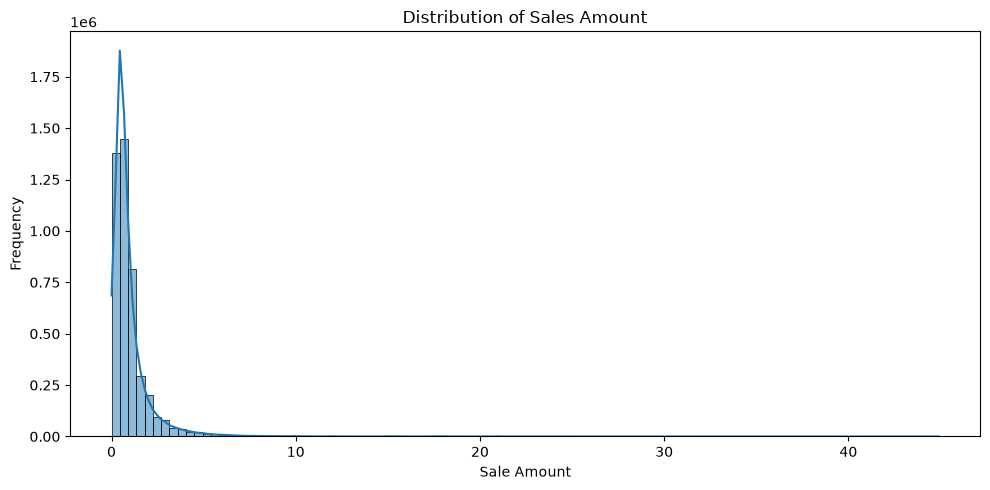

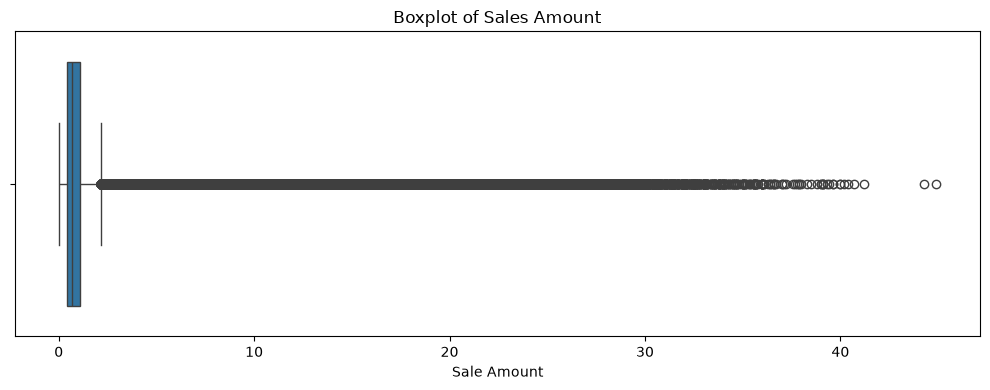

Zero-sales records: 4.46%


In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distribution of sales
plt.figure(figsize=(10, 5))
sns.histplot(cleaned_df["sale_amount"], bins=100, kde=True)
plt.title("Distribution of Sales Amount")
plt.xlabel("Sale Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Boxplot to identify extreme sales values
plt.figure(figsize=(10, 4))
sns.boxplot(x=cleaned_df["sale_amount"])
plt.title("Boxplot of Sales Amount")
plt.xlabel("Sale Amount")
plt.tight_layout()
plt.show()

# Percentage of zero-sales records
zero_sales_percentage = (
    (cleaned_df["sale_amount"] == 0).mean() * 100
)

print(f"Zero-sales records: {zero_sales_percentage:.2f}%")

**Interpretation of Sales Distribution**

The histogram and boxplot show that the `sale_amount` variable is strongly positively skewed (right-skewed).

- Most observations are concentrated around relatively low sales values.
- A long right tail indicates that a small proportion of observations have substantially higher sales.
- The boxplot identifies numerous potential upper-end outliers.
- The mean sales amount (approximately 0.999) is higher than the median (0.7), further indicating positive skewness.

**Impact on Machine Learning Models**

This skewed distribution may affect model performance. In particular, regression models that are sensitive to extreme values may be influenced disproportionately by observations with very high sales.

**Planned Treatment**

We will not remove high-sales observations automatically because they may represent genuine sales activity.

Instead, we will:

1. Investigate extreme values to distinguish genuine high-sales observations from possible data errors.
2. Consider a logarithmic transformation using `log1p(sale_amount)` to reduce skewness.
3. Compare model performance with and without the transformation.
4. Evaluate final predictions on the original sales scale using appropriate regression metrics such as MAE, RMSE and WAPE.

The transformation will only be retained if it improves validation performance. The original `sale_amount` values will be preserved for interpretation and evaluation.

In [37]:
print("Sales skewness:", cleaned_df["sale_amount"].skew())

zero_sales_percentage = (
    (cleaned_df["sale_amount"] == 0).mean() * 100
)

print(f"Zero-sales records: {zero_sales_percentage:.2f}%")

Sales skewness: 8.471775179820986
Zero-sales records: 4.46%


**Additional Statistical Findings**

The calculated sales skewness is 8.47, confirming a strongly right-skewed distribution. Approximately 4.46% of records have zero sales. This indicates that zero-sales observations are present but do not dominate the dataset. The skewness will be considered during feature preparation and model development, with logarithmic transformation evaluated as an experimental approach rather than applied automatically.

### 4.3 Sales Trends Over Time

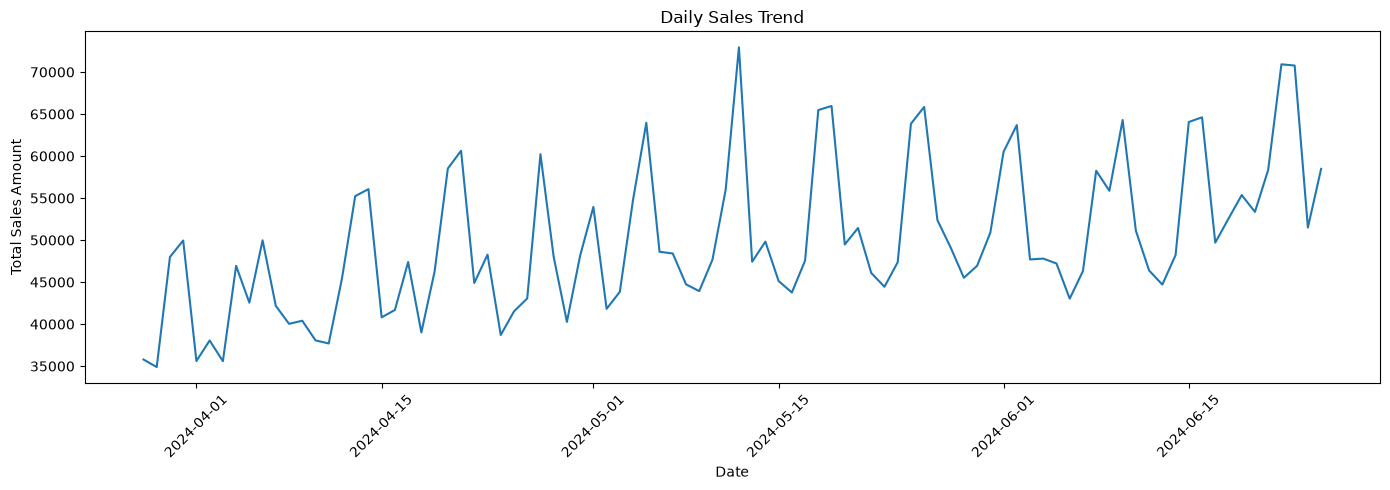

Number of dates: 90
Average daily sales: 49929.5643
Minimum daily sales: 34893.476
Maximum daily sales: 72938.825


In [38]:
# Aggregate sales by date
daily_sales = (
    cleaned_df.groupby("dt")["sale_amount"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(14, 5))
sns.lineplot(data=daily_sales, x="dt", y="sale_amount")

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Summary statistics
print("Number of dates:", daily_sales["dt"].nunique())
print("Average daily sales:", daily_sales["sale_amount"].mean())
print("Minimum daily sales:", daily_sales["sale_amount"].min())
print("Maximum daily sales:", daily_sales["sale_amount"].max())

**Interpretation of Daily Sales Trends**

The daily sales trend shows noticeable fluctuations throughout the 90-day observation period.

- Daily sales vary considerably, with a minimum of approximately 34,893 and a maximum of approximately 72,939.
- Several recurring peaks and declines are visible, suggesting possible weekly or other periodic sales patterns.
- Overall sales show some variation over time, but the graph alone does not establish a consistent upward or downward trend.
- These fluctuations may be associated with holidays, promotional activities, discounts, product availability, or other factors.

**Relevance to the Machine Learning Approach**

Although this project does not use traditional time-series forecasting methods, temporal patterns remain important. We will use date-based features and appropriately constructed historical sales features in supervised ML models.

A chronological data split will also be used to prevent future observations from leaking into model training.